# Лабораторная работа 10. Свёрточная нейронная сеть

## 1. Подготовка окружения

In [1]:
import os
import time
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from PIL import Image

os.makedirs("figures", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
torch.set_num_threads(4)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Устройство:", device)
print("Потоков CPU:", torch.get_num_threads())


PyTorch: 2.10.0+cpu
Устройство: cpu
Потоков CPU: 4


## 2. Набор данных HDL

In [2]:
data_root = "datasets/HDL"
images_root = os.path.join(data_root, "ImagesDataset")

if not os.path.isdir(images_root):
    from huggingface_hub import snapshot_download
    snapshot_download(
        repo_id="gfbati/HDL",
        repo_type="dataset",
        local_dir=data_root,
        allow_patterns=["ImagesDataset/**", "README.md"],
    )

print("Каталог с изображениями:", images_root)
print("Классы:", sorted(os.listdir(images_root)))


Каталог с изображениями: datasets/HDL\ImagesDataset
Классы: ['AND', 'BUFFER', 'NAND', 'NOR', 'NOT', 'OR', 'XNOR', 'XOR']


Всего изображений: 1200
Число классов: 8
AND     : 150
BUFFER  : 150
NAND    : 150
NOR     : 150
NOT     : 150
OR      : 150
XNOR    : 150
XOR     : 150
Ширина: min=61, median=428, max=2776
Высота: min=27, median=214, max=2267
Соотношение сторон: min=0.20, median=2.40, max=7.97


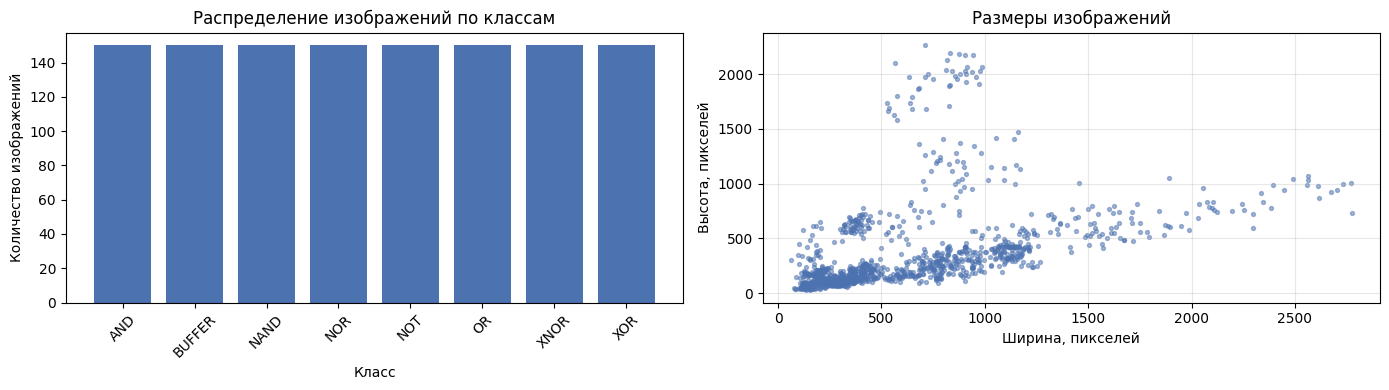

In [3]:
dataset = datasets.ImageFolder(images_root)
classes = dataset.classes
targets = np.array(dataset.targets)
counts = np.bincount(targets, minlength=len(classes))

print("Всего изображений:", len(dataset))
print("Число классов:", len(classes))
for name, cnt in zip(classes, counts):
    print(f"{name:8s}: {cnt}")

sizes = []
for path, _ in dataset.samples:
    with Image.open(path) as im:
        sizes.append((im.width, im.height))
sizes = np.array(sizes)
aspect = sizes[:, 0] / sizes[:, 1]

print("Ширина: min=%d, median=%.0f, max=%d" % (sizes[:, 0].min(), np.median(sizes[:, 0]), sizes[:, 0].max()))
print("Высота: min=%d, median=%.0f, max=%d" % (sizes[:, 1].min(), np.median(sizes[:, 1]), sizes[:, 1].max()))
print("Соотношение сторон: min=%.2f, median=%.2f, max=%.2f" % (aspect.min(), np.median(aspect), aspect.max()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(classes, counts, color="#4C72B0")
axes[0].set_title("Распределение изображений по классам")
axes[0].set_xlabel("Класс")
axes[0].set_ylabel("Количество изображений")
axes[0].tick_params(axis="x", rotation=45)
axes[1].scatter(sizes[:, 0], sizes[:, 1], s=8, alpha=0.5, color="#4C72B0")
axes[1].set_title("Размеры изображений")
axes[1].set_xlabel("Ширина, пикселей")
axes[1].set_ylabel("Высота, пикселей")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig01_dataset_overview.png", dpi=150, bbox_inches="tight")
plt.show()


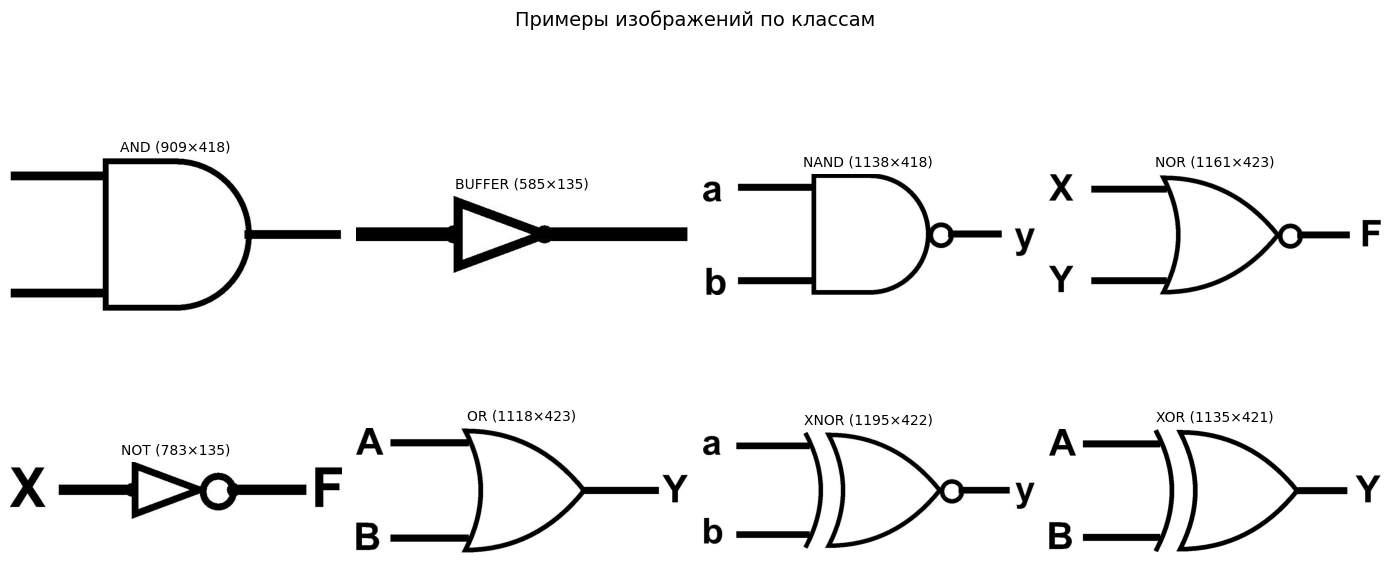

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, cls_idx in zip(axes.ravel(), range(len(classes))):
    path = next(p for p, y in dataset.samples if y == cls_idx)
    im = Image.open(path).convert("RGB")
    ax.imshow(im)
    ax.set_title(f"{classes[cls_idx]} ({im.width}×{im.height})", fontsize=10)
    ax.axis("off")
plt.suptitle("Примеры изображений по классам", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig02_class_examples.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Предобработка и аугментация

In [5]:
class PadToSquare:
    """Дополняет изображение белыми полями до квадрата, сохраняя пропорции."""
    def __call__(self, img):
        w, h = img.size
        side = max(w, h)
        canvas = Image.new("RGB", (side, side), (255, 255, 255))
        canvas.paste(img, ((side - w) // 2, (side - h) // 2))
        return canvas


IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomAffine(degrees=180, translate=(0.05, 0.05), scale=(0.9, 1.1), shear=5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = transforms.Compose([
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

idx = np.arange(len(dataset))
idx_train, idx_tmp = train_test_split(idx, test_size=0.3, random_state=SEED, stratify=targets)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=SEED, stratify=targets[idx_tmp])

train_ds = Subset(datasets.ImageFolder(images_root, transform=train_tf), idx_train)
val_ds = Subset(datasets.ImageFolder(images_root, transform=eval_tf), idx_val)
test_ds = Subset(datasets.ImageFolder(images_root, transform=eval_tf), idx_test)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=0)

print("Обучающая выборка:", len(train_ds))
print("Валидационная выборка:", len(val_ds))
print("Тестовая выборка:", len(test_ds))


Обучающая выборка: 840
Валидационная выборка: 180
Тестовая выборка: 180


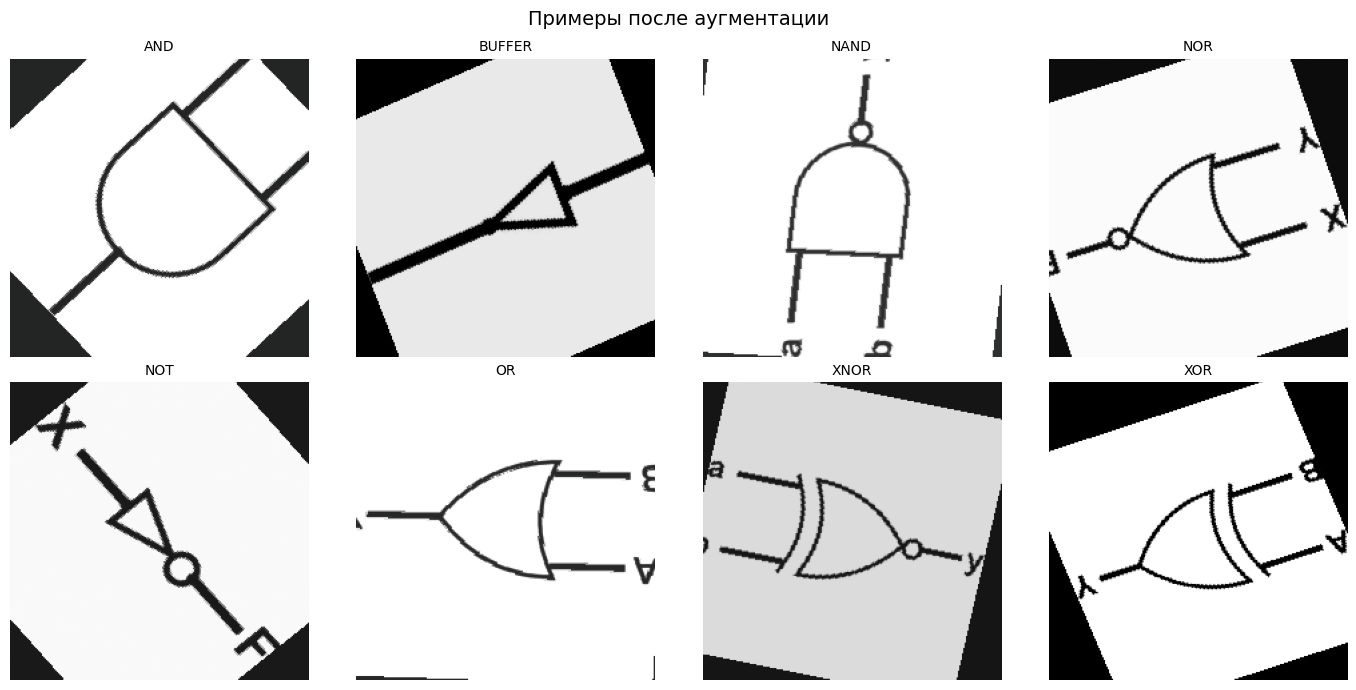

In [6]:
mean_t = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_t = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, cls_idx in zip(axes.ravel(), range(len(classes))):
    path = next(p for p, y in dataset.samples if y == cls_idx)
    im = Image.open(path).convert("RGB")
    x = train_tf(im)
    x = (x * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(x)
    ax.set_title(classes[cls_idx], fontsize=10)
    ax.axis("off")
plt.suptitle("Примеры после аугментации", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig03_augmentation.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Архитектура сети

In [7]:
def build_model(num_classes):
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes),
    )
    return model


model = build_model(len(classes)).to(device)
n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Всего параметров: {n_params:,}")
print(f"Обучаемых параметров: {n_trainable:,}")
print(model.classifier)


Всего параметров: 4,017,796
Обучаемых параметров: 4,017,796
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=8, bias=True)
)


## 5. Обучение

In [8]:
NUM_EPOCHS = 8
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
val_criterion = nn.CrossEntropyLoss()

backbone_params = []
head_params = []
for name, param in model.named_parameters():
    if name.startswith("classifier"):
        head_params.append(param)
    else:
        backbone_params.append(param)

print("Параметров backbone:", sum(p.numel() for p in backbone_params))
print("Параметров классификатора:", sum(p.numel() for p in head_params))

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)


def compute_grad_norm(params):
    total = 0.0
    for p in params:
        if p.grad is not None:
            total += p.grad.detach().pow(2).sum().item()
    return total ** 0.5


def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = val_criterion(logits, y)
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


history = {
    "epoch": [], "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [],
    "grad_norm": [], "grad_norm_backbone": [], "grad_norm_head": [],
    "lr_backbone": [], "lr_head": [],
}

best_val_acc = 0.0
best_path = "artifacts/best_hdl_cnn.pth"

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    running_correct = 0
    running_total = 0
    grad_norms = []
    grad_norms_backbone = []
    grad_norms_head = []
    start = time.time()

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        grad_norms.append(compute_grad_norm(model.parameters()))
        grad_norms_backbone.append(compute_grad_norm(backbone_params))
        grad_norms_head.append(compute_grad_norm(head_params))

        optimizer.step()

        running_loss += loss.item() * x.size(0)
        running_correct += (logits.argmax(1) == y).sum().item()
        running_total += x.size(0)

    scheduler.step()
    train_loss = running_loss / running_total
    train_acc = running_correct / running_total
    val_loss, val_acc = evaluate(model, val_loader)

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["grad_norm"].append(float(np.mean(grad_norms)))
    history["grad_norm_backbone"].append(float(np.mean(grad_norms_backbone)))
    history["grad_norm_head"].append(float(np.mean(grad_norms_head)))
    history["lr_backbone"].append(optimizer.param_groups[0]["lr"])
    history["lr_head"].append(optimizer.param_groups[0]["lr"])

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_path)

    print(f"Эпоха {epoch:2d}/{NUM_EPOCHS} | train loss {train_loss:.4f} | train acc {train_acc:.3f} | "
          f"val loss {val_loss:.4f} | val acc {val_acc:.3f} | grad norm {np.mean(grad_norms):.3f} | "
          f"{time.time() - start:.1f} с")

print("Лучшая валидационная точность:", round(best_val_acc, 4))


Параметров backbone: 4007548
Параметров классификатора: 10248


Эпоха  1/8 | train loss 1.7737 | train acc 0.304 | val loss 1.1270 | val acc 0.467 | grad norm 4.085 | 96.3 с


Эпоха  2/8 | train loss 1.1094 | train acc 0.617 | val loss 0.5587 | val acc 0.806 | grad norm 3.748 | 96.2 с


Эпоха  3/8 | train loss 0.7693 | train acc 0.805 | val loss 0.4451 | val acc 0.872 | grad norm 3.497 | 95.7 с


Эпоха  4/8 | train loss 0.6110 | train acc 0.871 | val loss 0.5039 | val acc 0.850 | grad norm 2.824 | 96.4 с


Эпоха  5/8 | train loss 0.5145 | train acc 0.913 | val loss 0.2695 | val acc 0.911 | grad norm 2.520 | 95.8 с


Эпоха  6/8 | train loss 0.4979 | train acc 0.926 | val loss 0.2144 | val acc 0.944 | grad norm 2.195 | 95.9 с


Эпоха  7/8 | train loss 0.4423 | train acc 0.951 | val loss 0.1653 | val acc 0.967 | grad norm 1.955 | 96.0 с


Эпоха  8/8 | train loss 0.4184 | train acc 0.954 | val loss 0.1664 | val acc 0.967 | grad norm 2.038 | 96.2 с
Лучшая валидационная точность: 0.9667


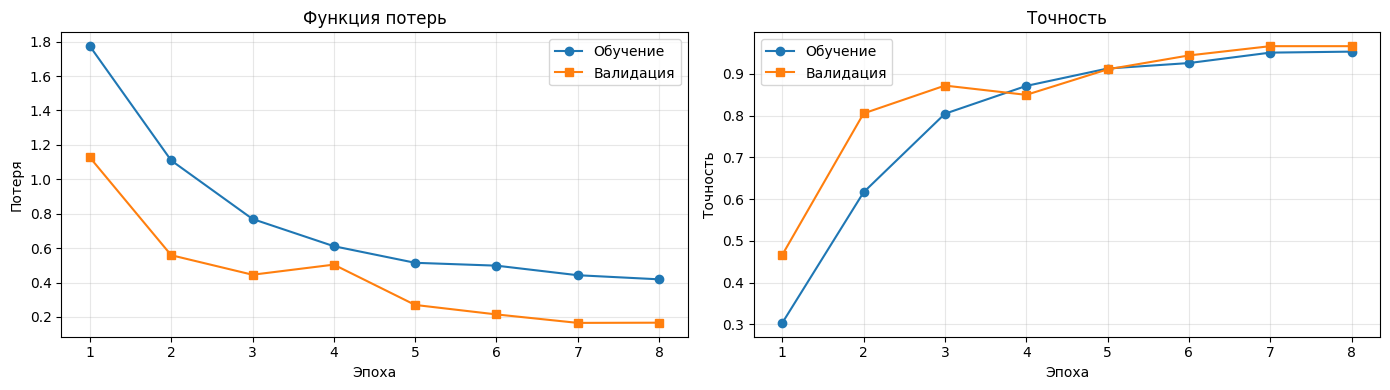

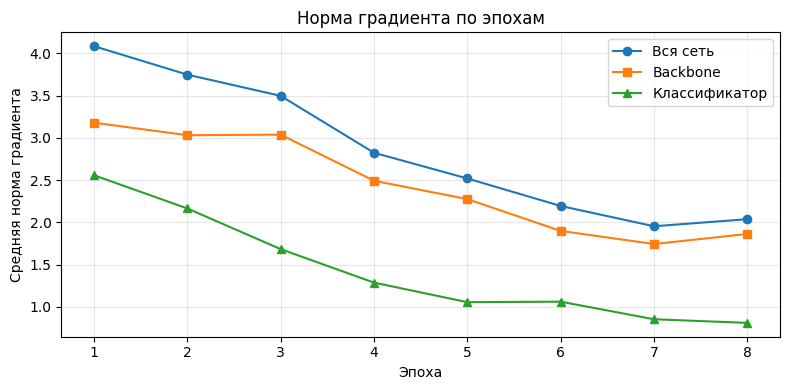

In [9]:
epochs = history["epoch"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(epochs, history["train_loss"], marker="o", label="Обучение")
axes[0].plot(epochs, history["val_loss"], marker="s", label="Валидация")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Потеря")
axes[0].set_title("Функция потерь")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(epochs, history["train_acc"], marker="o", label="Обучение")
axes[1].plot(epochs, history["val_acc"], marker="s", label="Валидация")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Точность")
axes[1].set_title("Точность")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig04_loss_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs, history["grad_norm"], marker="o", label="Вся сеть")
plt.plot(epochs, history["grad_norm_backbone"], marker="s", label="Backbone")
plt.plot(epochs, history["grad_norm_head"], marker="^", label="Классификатор")
plt.xlabel("Эпоха")
plt.ylabel("Средняя норма градиента")
plt.title("Норма градиента по эпохам")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig05_gradients.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Оценка на тестовой выборке

In [10]:
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

y_true = []
y_pred = []
test_loss = 0.0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        test_loss += val_criterion(logits, y).item() * x.size(0)
        y_true.extend(y.cpu().numpy().tolist())
        y_pred.extend(logits.argmax(1).cpu().numpy().tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
test_loss /= len(test_ds)
test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average="macro")

print(f"Тестовая потеря: {test_loss:.4f}")
print(f"Тестовая точность: {test_acc:.4f}")
print(f"Macro F1: {test_f1:.4f}")
print(classification_report(y_true, y_pred, target_names=classes, digits=3))


Тестовая потеря: 0.1257
Тестовая точность: 0.9833
Macro F1: 0.9836
              precision    recall  f1-score   support

         AND      1.000     1.000     1.000        22
      BUFFER      0.957     1.000     0.978        22
        NAND      1.000     0.957     0.978        23
         NOR      0.958     1.000     0.979        23
         NOT      0.957     0.957     0.957        23
          OR      1.000     1.000     1.000        22
        XNOR      1.000     0.957     0.978        23
         XOR      1.000     1.000     1.000        22

    accuracy                          0.983       180
   macro avg      0.984     0.984     0.984       180
weighted avg      0.984     0.983     0.983       180



In [11]:
def predict_tta(model, loader, n_rot=4):
    model.eval()
    all_true = []
    all_prob = []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            prob = torch.zeros(x.size(0), len(classes), device=device)
            for k in range(n_rot):
                xr = torch.rot90(x, k, dims=(2, 3)).contiguous()
                prob += torch.softmax(model(xr), dim=1)
            all_prob.append((prob / n_rot).cpu())
            all_true.append(y)
    return torch.cat(all_true).numpy(), torch.cat(all_prob).numpy()


y_true_tta, y_prob_tta = predict_tta(model, test_loader)
y_pred_tta = y_prob_tta.argmax(1)
tta_acc = accuracy_score(y_true_tta, y_pred_tta)
tta_f1 = f1_score(y_true_tta, y_pred_tta, average="macro")
print(f"TTA (4 поворота): accuracy={tta_acc:.4f}, macro F1={tta_f1:.4f}")

if tta_acc >= test_acc:
    final_pred = y_pred_tta
    final_acc = tta_acc
    final_f1 = tta_f1
    print("Для итоговых метрик используется TTA.")
else:
    final_pred = y_pred
    final_acc = test_acc
    final_f1 = test_f1
    print("Для итоговых метрик используется однократный проход.")


TTA (4 поворота): accuracy=0.9722, macro F1=0.9725
Для итоговых метрик используется однократный проход.


In [12]:
metrics = {
    "test_loss": float(test_loss),
    "test_acc": float(test_acc),
    "test_f1": float(test_f1),
    "tta_acc": float(tta_acc),
    "tta_f1": float(tta_f1),
    "final_acc": float(final_acc),
    "final_f1": float(final_f1),
    "best_val_acc": float(best_val_acc),
    "n_train": len(train_ds),
    "n_val": len(val_ds),
    "n_test": len(test_ds),
}
with open("artifacts/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
pd.DataFrame({"y_true": y_true, "y_pred": final_pred}).to_csv("artifacts/test_predictions.csv", index=False)
print(metrics)


{'test_loss': 0.12570377621385787, 'test_acc': 0.9833333333333333, 'test_f1': 0.9835723095898858, 'tta_acc': 0.9722222222222222, 'tta_f1': 0.972463768115942, 'final_acc': 0.9833333333333333, 'final_f1': 0.9835723095898858, 'best_val_acc': 0.9666666666666667, 'n_train': 840, 'n_val': 180, 'n_test': 180}


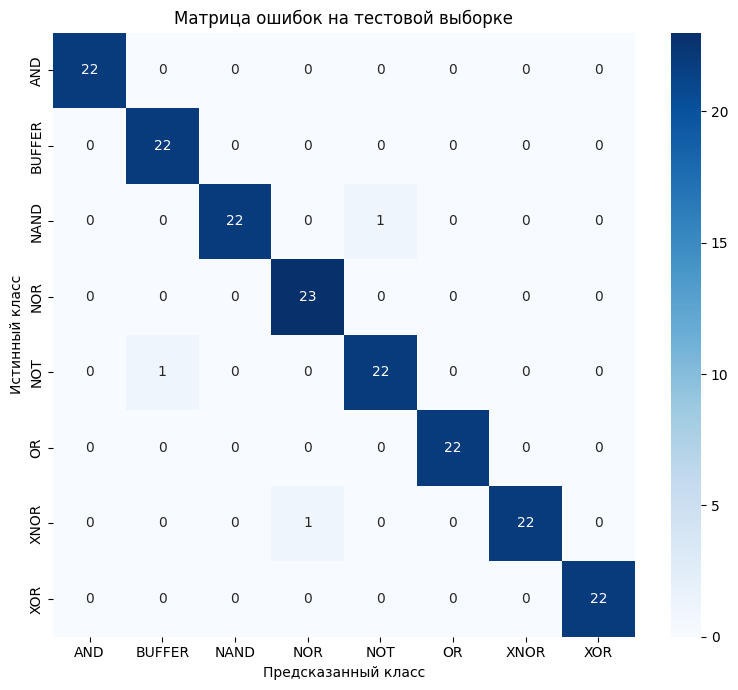

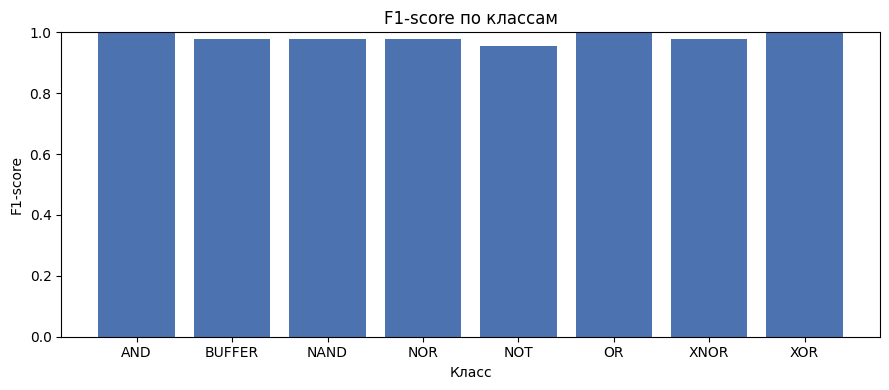

In [13]:
cm = confusion_matrix(y_true, final_pred)
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Матрица ошибок на тестовой выборке")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.tight_layout()
plt.savefig("figures/fig06_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

report_dict = classification_report(y_true, final_pred, target_names=classes, output_dict=True)
with open("artifacts/classification_report.json", "w", encoding="utf-8") as f:
    json.dump(report_dict, f, ensure_ascii=False, indent=2)
f1_scores = [report_dict[c]["f1-score"] for c in classes]
plt.figure(figsize=(9, 4))
plt.bar(classes, f1_scores, color="#4C72B0")
plt.ylim(0, 1)
plt.title("F1-score по классам")
plt.xlabel("Класс")
plt.ylabel("F1-score")
plt.tight_layout()
plt.savefig("figures/fig07_per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()


Количество ошибок: 3


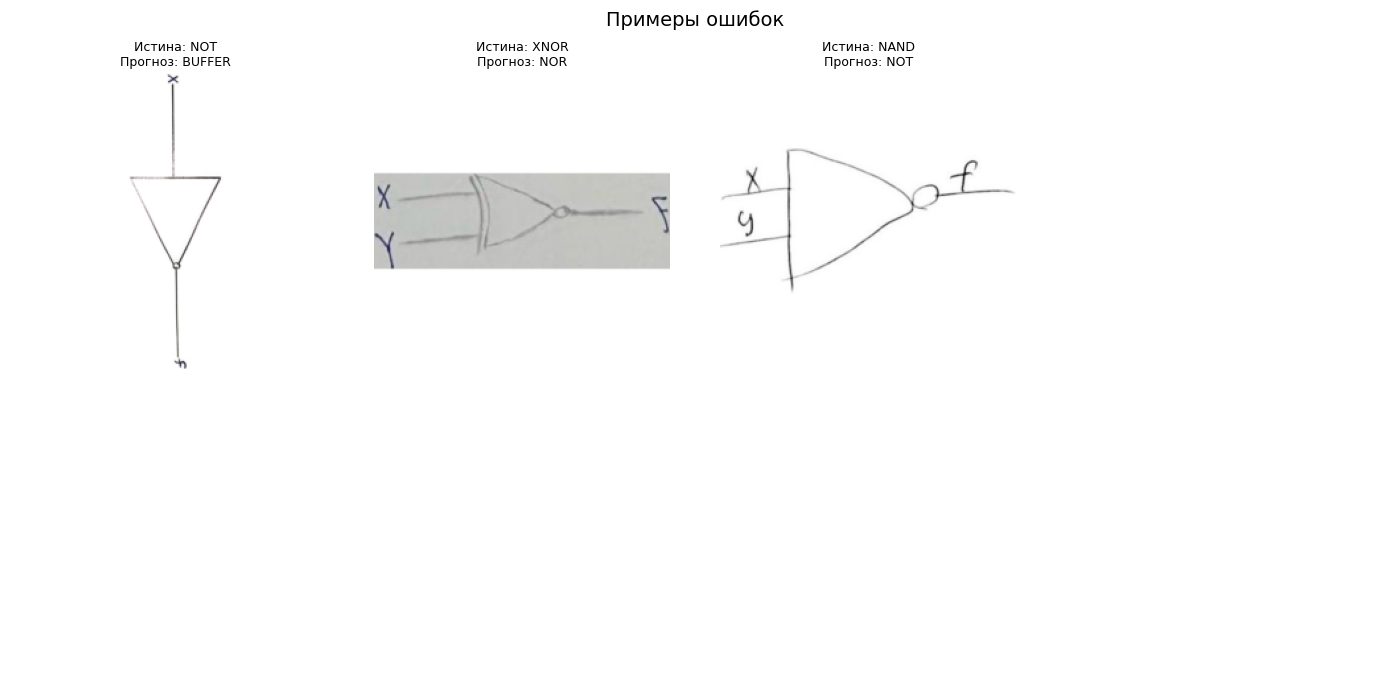

In [14]:
wrong_idx = np.where(y_true != final_pred)[0]
print("Количество ошибок:", len(wrong_idx))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()
for ax in axes:
    ax.axis("off")
for ax, i in zip(axes[:min(8, len(wrong_idx))], wrong_idx[:8]):
    img, true_label = test_ds[i]
    img = (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(f"Истина: {classes[true_label]}\nПрогноз: {classes[final_pred[i]]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Примеры ошибок", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig08_errors.png", dpi=150, bbox_inches="tight")
plt.show()


In [15]:
log_df = pd.DataFrame(history)
log_df.to_csv("artifacts/training_log.csv", index=False)
log_df.round(4)


,epoch,train_loss,train_acc,val_loss,val_acc,grad_norm,grad_norm_backbone,grad_norm_head,lr_backbone,lr_head
0,1,1.7737,0.3036,1.1270,0.4667,4.0849,3.1798,2.5586,0.0010,0.0010
1,2,1.1094,0.6167,0.5587,0.8056,3.7484,3.0314,2.1654,0.0009,0.0009
2,3,0.7693,0.8048,0.4451,0.8722,3.4973,3.0384,1.6843,0.0007,0.0007
3,4,0.6110,0.8714,0.5039,0.8500,2.8241,2.4931,1.2881,0.0005,0.0005
4,5,0.5145,0.9131,0.2695,0.9111,2.5200,2.2758,1.0567,0.0003,0.0003
5,6,0.4979,0.9262,0.2144,0.9444,2.1947,1.8996,1.0624,0.0001,0.0001
6,7,0.4423,0.9512,0.1653,0.9667,1.9546,1.7445,0.8546,0.0000,0.0000
7,8,0.4184,0.9536,0.1664,0.9667,2.0381,1.8630,0.8115,0.0000,0.0000
